# Posterior versus dynamics — KL divergence

Checkpoint: `ls6hfsbu/00081600`, the earlier ARC run used in the regenerated four-pane clip. Both figures use the same **64 episodes**.

At each environment step, compare the posterior conditioned on real observations, $q_t$, with the dynamics model's open-loop output distribution, $p_t$:

$$D_t = \frac{1}{N_z}\sum_{i=1}^{N_z}\sum_k q_{t,i}(k)\log\frac{q_{t,i}(k)}{p_{t,i}(k)}.$$

Units are **nats per categorical latent factor**; lower means closer agreement. Each plot contains one mean KL curve and its 95% confidence band.


The two plots differ only in the actions supplied to the open-loop dynamics model:

- **Actual actions:** use the actions taken by the policy in the real environment. This measures prediction drift along the observed trajectory.
- **Imagined actions:** the actor chooses actions from its imagined state. The reference posterior still comes from the real trajectory, so this divergence also reflects different driving decisions.

Both open loops receive five initial observations and then predict continuously without further image corrections. The real posterior continues to receive observations every step.

Each curve is the **mean across episodes**. The pointwise 95% bootstrap intervals resample **whole episodes**, keeping time points and conditions paired. They describe evaluation uncertainty for this fixed checkpoint, rather than variation across training seeds.

The plotted horizon stops at the shortest episode, so **all 64 episodes contribute at every point**. Longer trajectories remain in the NPZ. Re-running this notebook uses saved trajectories and does not run environments.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np

repo_root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "pyproject.toml").is_file()
    and (parent / "notebooks/plot_generation").is_dir()
)


## Settings

Edit the dataset, styling and export path here. Enable `recompute_ci` to resample the saved trajectories using rliable. Both plots share the same axis limits for comparison.


In [2]:
data_prefix = repo_root / "experiments/dreamer/divergence/ls6hfsbu-00081600-64"
export_stem = repo_root / "assets/arc-latent-divergence"

plot_conditions = ["open_loop_matched_actions", "open_loop_actor"]
plot_settings = {
    "open_loop_matched_actions": {"title": "ACTUAL ACTIONS", "suffix": ""},
    "open_loop_actor": {"title": "IMAGINED ACTIONS", "suffix": "-imagined-actions"},
}
recompute_ci = False
bootstrap_reps = 10_000
bootstrap_seed = 500_000

blk = "#343633"
off_white = "#F7F4EB"
figure_size = (8.5, 4.0)
ci_alpha = 0.15

plt.rcParams.update({
    "font.family": "Routed Gothic", "font.style": "normal", "font.size": 11,
    "figure.facecolor": off_white, "axes.facecolor": off_white, "figure.dpi": 120,
    "text.color": blk, "axes.labelcolor": blk, "axes.edgecolor": blk,
    "xtick.color": blk, "ytick.color": blk, "svg.fonttype": "none",
})


## Load the completed diagnostic

The stored curves include each valid terminal observation but exclude subsequent environment resets. The first five observations initialize both open loops; neither receives later real images.

In [3]:
report = json.loads(data_prefix.with_suffix(".json").read_text())
with np.load(data_prefix.with_suffix(".npz")) as archive:
    curves = archive["kl_curves"]
    episode_lengths = archive["episode_lengths"]

conditions = report["conditions"]
steps = np.asarray(report["steps"])
assert curves.shape[0] == report["num_episodes"] == 64
assert steps[-1] == episode_lengths.min()
assert np.isfinite(curves[:, steps]).all()
assert report["confidence_level"] == 0.95

mean = np.asarray(report["mean"])
ci_low = np.asarray(report["ci_low"])
ci_high = np.asarray(report["ci_high"])
if recompute_ci:
    from dreamer.divergence import bootstrap_curve_mean

    mean, interval = bootstrap_curve_mean(
        curves[:, steps], reps=bootstrap_reps, seed=bootstrap_seed
    )
    ci_low, ci_high = interval

print(f"Run: {report['checkpoint_metadata']['train_args']['name']}")
print(f"Checkpoint updates: {report['checkpoint_metadata']['train_step']:,}")
print(f"Episodes: {report['num_episodes']}; initial observations: {report['context']}")
print(f"Common horizon: environment steps {steps[0]}–{steps[-1]}")
print(f"Full episode lengths: {episode_lengths.min()}–{episode_lengths.max()} transitions")
print("\nMean KL at the final common step (nats per factor):")
for name in plot_conditions:
    index = conditions.index(name)
    print(f"{name}: {mean[-1, index]:.3f} [{ci_low[-1, index]:.3f}, {ci_high[-1, index]:.3f}]")


Run: arc-9195528
Checkpoint updates: 81,600
Episodes: 64; initial observations: 5
Common horizon: environment steps 5–622
Full episode lengths: 622–1000 transitions

Mean KL at the final common step (nats per factor):
open_loop_matched_actions: 1.914 [1.802, 2.029]
open_loop_actor: 1.757 [1.513, 2.004]


## Plot and export

Each figure contains one KL curve and a pointwise 95% episode-bootstrap band. No time smoothing is applied. The helper applies identical styling and axis limits to the two figures.


In [4]:
y_max = max(ci_high[:, conditions.index(name)].max() for name in plot_conditions) * 1.08


def plot_divergence(name):
    index = conditions.index(name)
    settings = plot_settings[name]
    fig, ax = plt.subplots(figsize=figure_size)
    ax.fill_between(
        steps, ci_low[:, index], ci_high[:, index],
        color=blk, alpha=ci_alpha, linewidth=0,
    )
    ax.plot(steps, mean[:, index], color=blk, linewidth=1.5)

    ax.set_title(f"POSTERIOR VS DYNAMICS - {settings['title']}", pad=18)
    ax.set_xlabel("ENVIRONMENT STEP")
    ax.set_ylabel("MEAN KL (NATS PER LATENT FACTOR)")
    ax.set_xlim(0, steps[-1])
    ax.set_ylim(0, y_max)
    ax.xaxis.set_major_locator(MultipleLocator(100))
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=blk, alpha=0.18, linestyle="--", linewidth=0.7)
    ax.spines[:].set_visible(False)
    ax.tick_params(axis="both", length=0, pad=8)
    plt.tight_layout()

    destination = export_stem.with_name(export_stem.name + settings["suffix"])
    destination.parent.mkdir(parents=True, exist_ok=True)
    for extension in (".png", ".svg"):
        fig.savefig(destination.with_suffix(extension), dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {destination.with_suffix('.png')}")


### Actual actions

The dynamics rollout receives the actions actually taken in the environment.


Saved /Users/alexinch/noodling/a2i/world_models_paper/assets/arc-latent-divergence.png


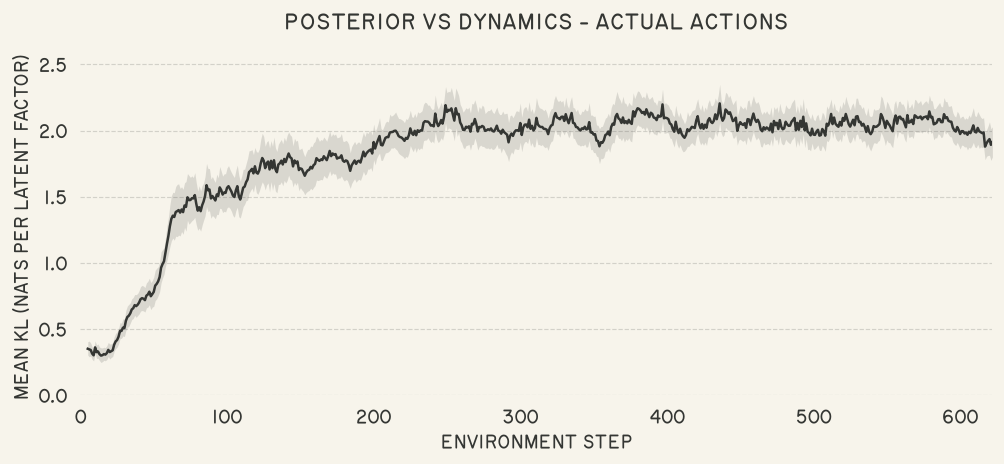

In [5]:
plot_divergence("open_loop_matched_actions")


### Imagined actions

The dynamics rollout receives actions chosen by the actor inside the model.


Saved /Users/alexinch/noodling/a2i/world_models_paper/assets/arc-latent-divergence-imagined-actions.png


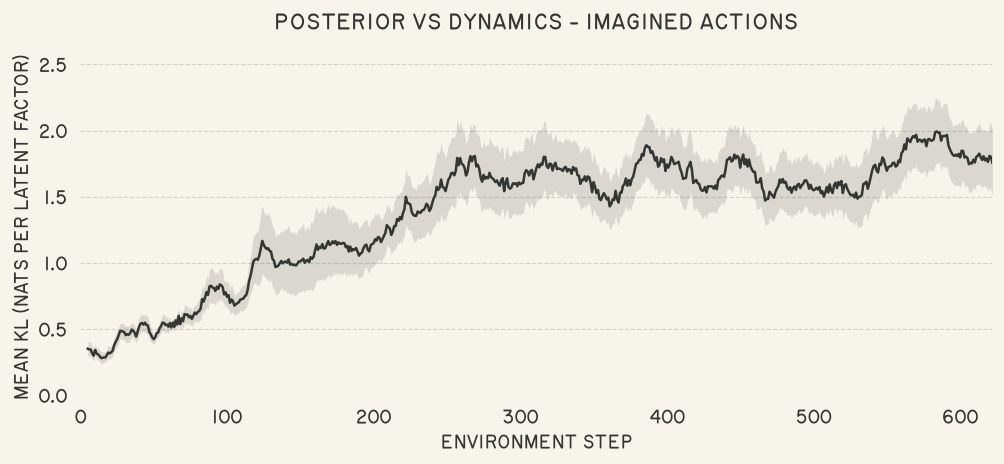

In [6]:
plot_divergence("open_loop_actor")
